In [36]:
import pandas as pd
from pathlib import Path
import numpy as np

data_dir = Path('../data')

df = pd.read_csv(data_dir/'used_cars.csv')

df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Brand         14993 non-null  object
 1   model         14993 non-null  object
 2   Year          14993 non-null  int64 
 3   Age           14993 non-null  int64 
 4   kmDriven      14905 non-null  object
 5   Transmission  14993 non-null  object
 6   Owner         14993 non-null  object
 7   FuelType      14993 non-null  object
 8   PostedDate    14993 non-null  object
 9   AdditionInfo  14993 non-null  object
 10  AskPrice      14993 non-null  object
dtypes: int64(2), object(9)
memory usage: 1.3+ MB


In [38]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Brand,14993,43,Maruti Suzuki,4615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,14993,436,Wagon-R,616,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,14993.0,NaN,NaN,NaN,2016.32215,4.343017,1900.0,2014.0,2017.0,2019.0,2024.0
Age,14993.0,NaN,NaN,NaN,7.67785,4.343017,0.0,5.0,7.0,10.0,124.0
kmDriven,14905,2718,"65,000 km",295,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,14993,2,Automatic,7618,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,14993,2,second,7794,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FuelType,14993,4,Petrol,5822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PostedDate,14993,13,Nov-24,13251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AdditionInfo,14993,10676,"BMW 3 Series GT 320d Luxury Line, 2015, Diesel",30,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [41]:
df.isnull().sum()

Brand            0
model            0
Year             0
Age              0
kmDriven        88
Transmission     0
Owner            0
FuelType         0
PostedDate       0
AdditionInfo     0
AskPrice         0
dtype: int64

In [44]:
df = df.dropna()
df.count()

Brand           14905
model           14905
Year            14905
Age             14905
kmDriven        14905
Transmission    14905
Owner           14905
FuelType        14905
PostedDate      14905
AdditionInfo    14905
AskPrice        14905
dtype: int64

In [45]:
df.duplicated().sum()

np.int64(996)

In [47]:
df = df.drop_duplicates()

df.duplicated().sum()

np.int64(0)

In [49]:
df['kmDriven'] = df['kmDriven'].str.replace(',', '').str.replace('km', '')
df['kmDriven']  = pd.to_numeric(df['kmDriven']).astype('int64')

df['kmDriven']

0         98000
1        190000
2         77246
3         83500
4         45000
          ...  
14988     31000
14989     45000
14990     60000
14991     62000
14992     18000
Name: kmDriven, Length: 13909, dtype: int64

In [50]:
df['AskPrice'].head()

0    ₹ 1,95,000
1    ₹ 3,75,000
2    ₹ 1,84,999
3    ₹ 5,65,000
4    ₹ 6,85,000
Name: AskPrice, dtype: object

In [51]:
df['AskPrice'] = df['AskPrice'].str[1:]

df['AskPrice']

0          1,95,000
1          3,75,000
2          1,84,999
3          5,65,000
4          6,85,000
            ...    
14988      5,75,000
14989     13,45,000
14990      1,60,000
14991      3,80,000
14992      4,50,000
Name: AskPrice, Length: 13909, dtype: object

In [52]:
df['AskPrice'] = df['AskPrice'].str.replace(',' , '')
df['AskPrice'] = pd.to_numeric(df['AskPrice']).astype('int64')

df['AskPrice'].head()

0    195000
1    375000
2    184999
3    565000
4    685000
Name: AskPrice, dtype: int64

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13909 entries, 0 to 14992
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Brand         13909 non-null  object
 1   model         13909 non-null  object
 2   Year          13909 non-null  int64 
 3   Age           13909 non-null  int64 
 4   kmDriven      13909 non-null  int64 
 5   Transmission  13909 non-null  object
 6   Owner         13909 non-null  object
 7   FuelType      13909 non-null  object
 8   PostedDate    13909 non-null  object
 9   AdditionInfo  13909 non-null  object
 10  AskPrice      13909 non-null  int64 
dtypes: int64(4), object(7)
memory usage: 1.3+ MB


In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

{'whiskers': [<matplotlib.lines.Line2D at 0x2126761da90>,
 'caps': [<matplotlib.lines.Line2D at 0x2126761dd10>,
 'boxes': [<matplotlib.lines.Line2D at 0x2126761d950>],
 'medians': [<matplotlib.lines.Line2D at 0x2126761df90>],
 'fliers': [<matplotlib.lines.Line2D at 0x2126761e0d0>],
 'means': []}

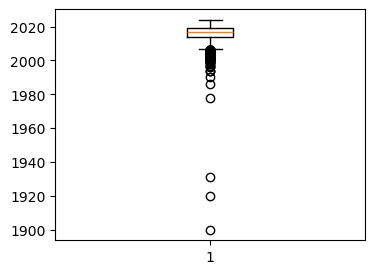

In [54]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize = (4, 3))
plt.boxplot(df['Year'])

{'whiskers': [<matplotlib.lines.Line2D at 0x212673a9590>,
 'caps': [<matplotlib.lines.Line2D at 0x212673a9810>,
 'boxes': [<matplotlib.lines.Line2D at 0x212673a9450>],
 'medians': [<matplotlib.lines.Line2D at 0x212673a9a90>],
 'fliers': [<matplotlib.lines.Line2D at 0x212673a9bd0>],
 'means': []}

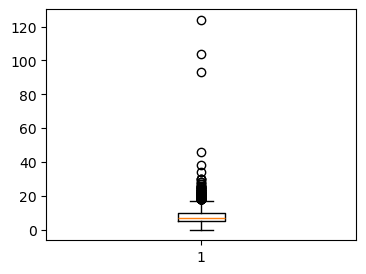

In [55]:
fig = plt.figure(figsize = (4, 3))
plt.boxplot(df['Age'])

In [56]:
df.query('Age > 120')

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
11392,Renault,Triber,1900,124,40000,Automatic,second,hybrid,Dec-24,Renault Triber 11 12 2019 CNG & Hybrids 40000 ...,440000


In [57]:
text_cols = df.select_dtypes(include="object").columns

for col in text_cols:
    df[col] = df[col].str.strip()

print(df.head())

           Brand      model  Year  Age  kmDriven Transmission   Owner  \
0          Honda       City  2001   23     98000       Manual  second   
1         Toyota     Innova  2009   15    190000       Manual  second   
2     Volkswagen  VentoTest  2010   14     77246       Manual   first   
3  Maruti Suzuki      Swift  2017    7     83500       Manual  second   
4  Maruti Suzuki     Baleno  2019    5     45000    Automatic   first   

  FuelType PostedDate                                       AdditionInfo  \
0   Petrol     Nov-24  Honda City v teck in mint condition, valid gen...   
1   Diesel     Jul-24  Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...   
2   Diesel     Nov-24  Volkswagen Vento 2010-2013 Diesel Breeze, 2010...   
3   Diesel     Nov-24     Maruti Suzuki Swift 2017 Diesel Good Condition   
4   Petrol     Nov-24       Maruti Suzuki Baleno Alpha CVT, 2019, Petrol   

   AskPrice  
0    195000  
1    375000  
2    184999  
3    565000  
4    685000  


In [58]:
df[["Year", "Age", "kmDriven", "AskPrice"]].describe()

,Year,Age,kmDriven,AskPrice
count,13909.000000,13909.000000,13909.000000,1.390900e+04
mean,2016.344813,7.655187,71520.714933,9.839511e+05
std,4.381162,4.381162,58349.577568,1.589664e+06
min,1900.000000,0.000000,0.000000,1.500000e+04
25%,2014.000000,5.000000,44000.000000,3.449990e+05
50%,2017.000000,7.000000,66000.000000,5.600000e+05
75%,2019.000000,10.000000,87000.000000,9.950000e+05
max,2024.000000,124.000000,980002.000000,4.250000e+07


In [64]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categoric_cols = df.select_dtypes(include=np.object_).columns.tolist()

print(f"numeric cols - {numeric_cols}")
print(f"categoric cols - {categoric_cols}")

numeric cols - ['Year', 'Age', 'kmDriven', 'AskPrice']
categoric cols - ['Brand', 'model', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo']


array([[<Axes: title={'center': 'Year'}>,
        <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'kmDriven'}>,
        <Axes: title={'center': 'AskPrice'}>]], dtype=object)

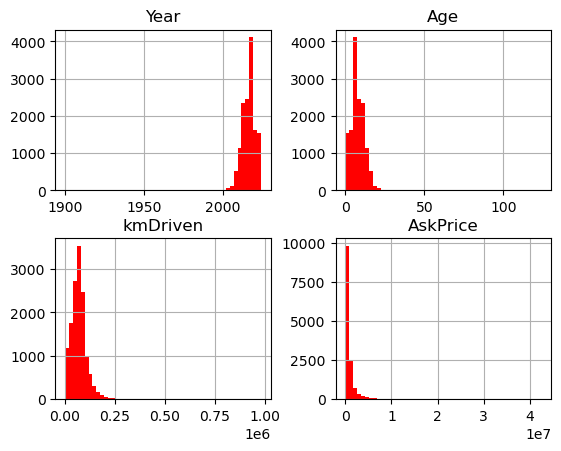

In [65]:
df.hist(bins = 50, color = 'red')

<Axes: xlabel='kmDriven', ylabel='AskPrice'>

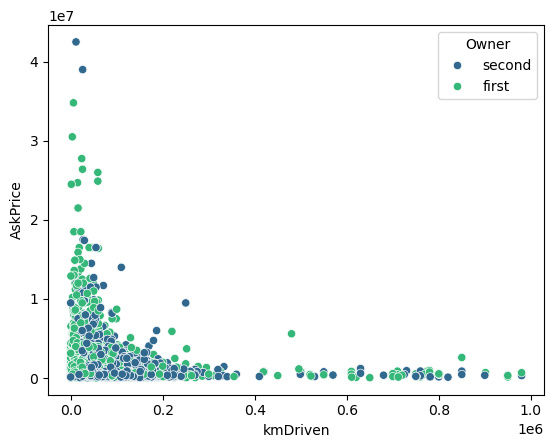

In [97]:
sns.scatterplot(df,x = 'kmDriven', y = 'AskPrice', hue='Owner', palette='viridis')

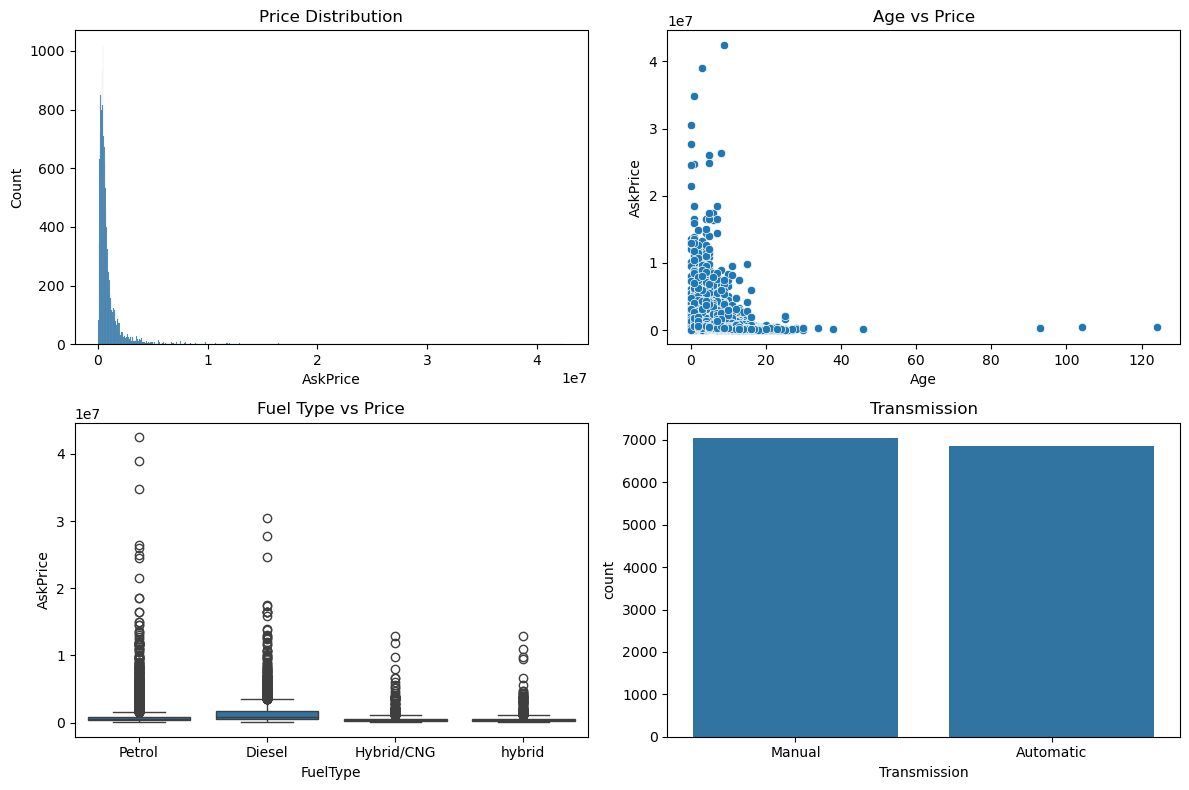

In [80]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
sns.histplot(df["AskPrice"])
plt.title("Price Distribution")

plt.subplot(2, 2, 2)
sns.scatterplot(data=df, x="Age", y="AskPrice")
plt.title("Age vs Price")

plt.subplot(2, 2, 3)
sns.boxplot(data=df, x="FuelType", y="AskPrice")
plt.title("Fuel Type vs Price")

plt.subplot(2, 2, 4)
sns.countplot(data=df, x="Transmission")
plt.title("Transmission")

plt.tight_layout()
plt.show()

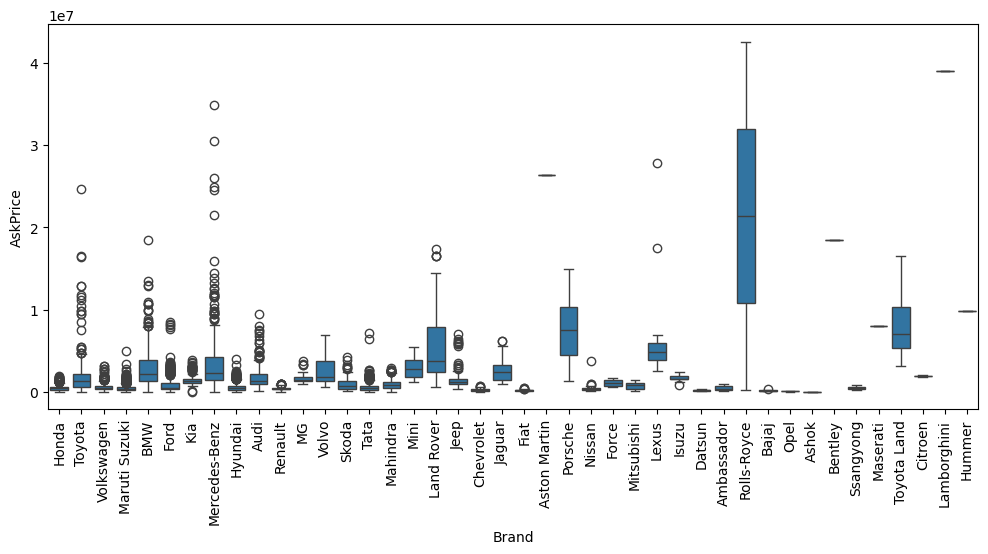

In [91]:
fig = plt.figure(figsize = (12, 5))
sns.boxplot(data=df, x="Brand", y="AskPrice")
plt.xticks(rotation=90)
plt.show()

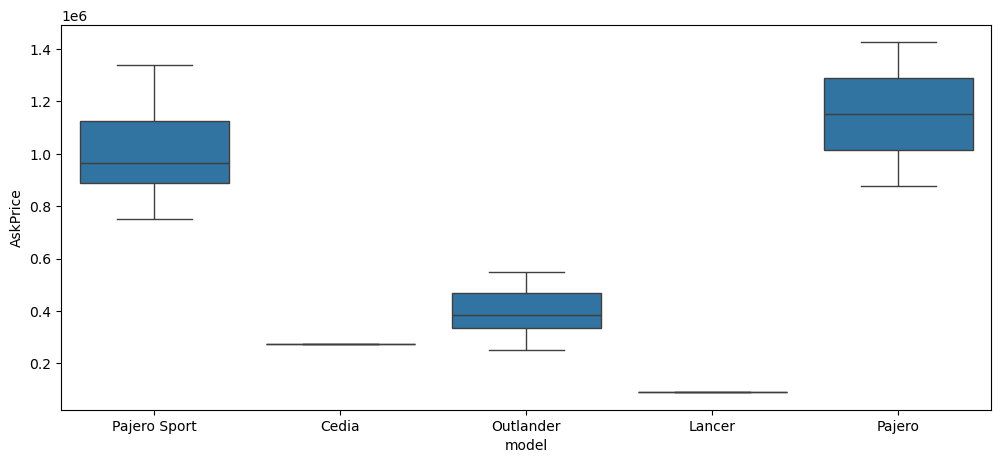

In [95]:
df_brand = df.query('Brand == "Mitsubishi" ')

fig = plt.figure(figsize = (12, 5))
sns.boxplot(data=df_brand, x="model", y="AskPrice")

plt.show()

<Axes: xlabel='Year', ylabel='AskPrice'>

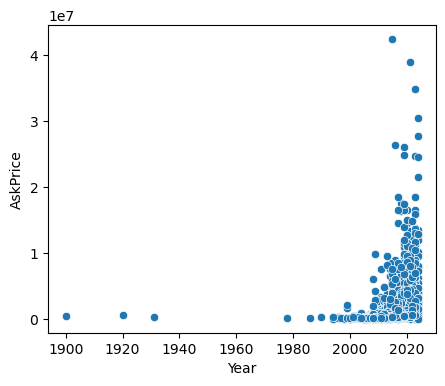

In [98]:
fig = plt.figure(figsize = (5, 4))
sns.scatterplot(data=df, y = 'AskPrice', x = 'Year')

In [130]:
df.groupby('Brand')['Brand'].count().sort_values()

Brand
Ashok               1
Aston Martin        1
Bentley             1
Hummer              1
Maserati            1
Lamborghini         1
Citroen             2
Opel                2
Rolls-Royce         2
Ambassador          3
Toyota Land         4
Bajaj               4
Ssangyong           5
Force               7
Isuzu              13
Mitsubishi         22
Porsche            27
Fiat               28
Lexus              28
Mini               40
Jaguar             47
Datsun             49
Volvo              63
Jeep               97
Land Rover         97
MG                108
Nissan            112
Chevrolet         125
Kia               211
Skoda             265
Audi              282
Renault           355
Ford              373
BMW               378
Volkswagen        445
Mercedes-Benz     536
Tata              568
Mahindra          714
Toyota           1044
Honda            1187
Hyundai          2308
Maruti Suzuki    4352
Name: Brand, dtype: int64

In [71]:
df.groupby('model')['model'].count().sort_values(ascending = False)

model
Wagon-R          587
City             511
Ertiga           421
Swift            393
Swift-Dzire      369
                ... 
Vanquish           1
Versa              1
Verito Vibe        1
Ventury            1
2.9 Sportback      1
Name: model, Length: 431, dtype: int64

In [101]:
df['Owner'].unique()

array(['second', 'first'], dtype=object)

In [102]:
df.columns

Index(['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner',
       'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice'],
      dtype='object')

In [103]:
df['Transmission'].unique()

array(['Manual', 'Automatic'], dtype=object)

<Axes: xlabel='FuelType', ylabel='count'>

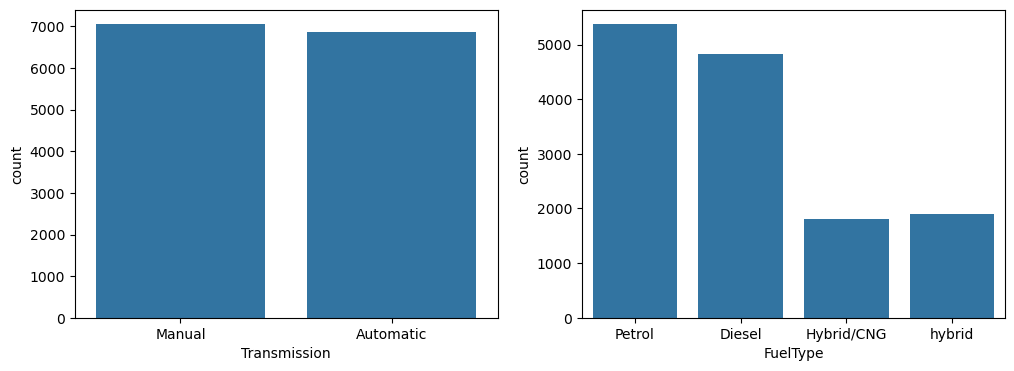

In [110]:
fig = plt.figure(figsize = (12, 4))
plt.subplot(1, 2, 1)
sns.countplot(df, x = 'Transmission')

plt.subplot(1, 2, 2)
sns.countplot(df, x = 'FuelType')

In [112]:
df['PostedDate'].unique()

array(['Nov-24', 'Jul-24', 'Oct-24', 'Aug-24', 'Sep-24', 'May-24',
       'Jun-24', 'Apr-24', 'Jan-24', 'Feb-24', 'Dec-23', 'Mar-24',
       'Dec-24'], dtype=object)

In [113]:
df = df.drop('PostedDate', axis = 1)

In [ ]:
df = df.rename(columns={'AdditionInfo': 'AdditionalInfo'})

In [133]:
df.groupby('AdditionalInfo')['AdditionalInfo'].count()

AdditionalInfo
*FOR SALE*                                                         1
0 chalaan \n Indica Vista   Well Maintained                        1
1 machine tk sell krna                                             1
1 want sell.my car Kia sonet black htk plus imt                    1
1 year validity baki 6 2025 12 mahina validity finish ho jayegi    1
                                                                  ..
सोनू शर्मा                                                         1
स्विफ्ट 2005 मॉडल पेट्रोल सीएनजी प्लस गाड़ी फुल ओके                1
हम 15 साल पुरानी गाड़ियां स्क्रैप मे लेते हैं                      1
ਗੱਡੀ ਬਿਲਕੁਲ ਸਾਫ ਹੈ ਸਰਵਿਸ ਹੋਈ ਹੈ                                    1
సూపర్ కండిషన్ 50%టైర్స్ బాగున్నవి                                  1
Name: AdditionalInfo, Length: 10604, dtype: int64

In [134]:
df = df.drop('AdditionalInfo', axis = 1)
df.columns

Index(['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner',
       'FuelType', 'AskPrice'],
      dtype='object')

In [138]:
df['Brand_avgPrice'] = df.groupby('Brand')['AskPrice'].transform('mean')

df['Brand_avgPrice']

0        5.055770e+05
1        1.738645e+06
2        6.717446e+05
3        4.790632e+05
4        4.790632e+05
             ...     
14988    4.790632e+05
14989    2.946173e+06
14990    4.790632e+05
14991    6.445226e+05
14992    4.790632e+05
Name: Brand_avgPrice, Length: 13909, dtype: float64

In [162]:
df['Model_avgPrice'] = df.groupby(['Brand', 'model'])['AskPrice'].transform('mean')

df['Model_avgPrice']

0        5.354427e+05
1        8.359548e+05
2        4.690525e+05
3        4.734328e+05
4        6.167689e+05
             ...     
14988    3.436421e+05
14989    1.873179e+06
14990    4.441667e+05
14991    3.312453e+05
14992    4.130016e+05
Name: Model_avgPrice, Length: 13909, dtype: float64

In [163]:
df.head()

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType,AskPrice,Brand_avgPrice,Model_avgPrice
0,honda,city,23,98000,0,0,Petrol,195000,5.055770e+05,535442.743640
1,toyota,innova,15,190000,0,0,Diesel,375000,1.738645e+06,835954.760274
2,volkswagen,ventotest,14,77246,0,1,Diesel,184999,6.717446e+05,469052.543860
3,maruti suzuki,swift,7,83500,0,0,Diesel,565000,4.790632e+05,473432.824427
4,maruti suzuki,baleno,5,45000,1,1,Petrol,685000,4.790632e+05,616768.929688


## usually Year and age is almost same . so no need to have both feature

In [141]:
df = df.drop('Year', axis = 1)
df.columns

Index(['Brand', 'model', 'Age', 'kmDriven', 'Transmission', 'Owner',
       'FuelType', 'AskPrice', 'Brand_avgPrice'],
      dtype='object')

In [149]:
df['Transmission'] = df['Transmission'].replace({'Manual':0, 'Automatic':1})
df['Owner'] = df['Owner'].replace({'first':1, 'second':0})
df['Owner'].head()

0    0
1    0
2    1
3    0
4    1
Name: Owner, dtype: int64

In [153]:
df["Brand"] = df["Brand"].str.lower().str.strip()
df["model"] = df["model"].str.lower().str.strip()

In [156]:
print(df["Brand"].nunique())
print(df["model"].nunique())

# print(df["Brand"].value_counts())
print(df["model"].value_counts())

42
428
model
wagon-r        587
city           511
ertiga         421
swift          393
swift-dzire    369
              ... 
versa            1
t-roc            1
x-trail          1
ventury          1
yeti             1
Name: count, Length: 428, dtype: int64


In [160]:
print((df["model"].value_counts() == 1).sum())

80


In [165]:
df.to_csv(data_dir/'clean.csv', index = False)
print("done")

done
